# Experimentación Comparativa de Visión Computacional (ResNet50 vs. EfficientNetB0)
**Asistente Inteligente para la Inspección Visual y Trazabilidad de Daños en Empaques**  

---

### Objetivo del Cuaderno:
Implementar, entrenar y comparar dos arquitecturas de **Redes Neuronales Convolucionales (CNN) mediante Transferencia de Aprendizaje (*Transfer Learning*)** para clasificar empaques durante la recepción en almacén (`damagedpackages` vs. `undamagedpackages`):

1. **Exploración y Preparación del Dataset Visual**:
   - Carga estructurada de las particiones `train` (3,742 imágenes), `valid` (302 imágenes) y `test` (102 imágenes) redimensionadas a $224 \times 224$ píxeles.
   - Balanceo mediante pesos de clase (`class_weight`) y aumento de datos (*Data Augmentation*).
2. **Comparativa de Arquitecturas con Transfer Learning**:
   - **Modelo 1 — ResNet50**: Red residual profunda de 50 capas con conexiones de salto (*skip connections*).
   - **Modelo 2 — EfficientNetB0**: Arquitectura de escalado compuesto eficiente en parámetros y operaciones.
   - Entrenamiento en **2 etapas** sobre GPU: *Extracción de Características* (base congelada) + *Fine-Tuning* (ajuste fino de capas superiores).
3. **Evaluación Rigurosa con las 5 Evidencias Exigidas por la Rúbrica**:
   - **1. Accuracy (Exactitud)**
   - **2. Precision (Precisión)**
   - **3. Recall (Sensibilidad / Exhaustividad)**
   - **4. F1-Score**
   - **5. Matriz de Confusión**
4. **Selección y Exportación del Modelo Ganador**:
   - Persistencia del modelo de mejor desempeño en `models/clasificador_cajas.keras` y `models/metadata_vision.json` para su integración multimodal con el asistente conversacional.


## 1. Configuración del Entorno (Google Colab GPU / Local) y Librerías
Este bloque detecta automáticamente si el cuaderno se está ejecutando en **Google Colab** (con aceleración GPU) o en un entorno local.

> **Instrucción para Google Colab:**  
> Subir carpeta comprimida como `dataset_img.zip` a la raíz de Colab (o Google Drive), la celda siguiente la descomprimirá automáticamente si aún no existe la carpeta.


In [30]:
from google.colab import drive
drive.mount('/content/drive')

EN_COLAB = True

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
import zipfile
from pathlib import Path

# Ruta al archivo zip en tu Google Drive
ruta_zip_drive = Path("/content/drive/MyDrive/dataset_img.zip")
# Ruta de destino en el disco local de la máquina de Colab
ruta_destino_colab = Path("/content/data")

if ruta_zip_drive.exists():
    print(f"[INFO] Detectado {ruta_zip_drive} en Google Drive.")
    if not (ruta_destino_colab / "dataset_img").exists():
        print("[INFO] Descomprimiendo dataset en el almacenamiento local de Colab...")
        ruta_destino_colab.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(ruta_zip_drive, "r") as zip_ref:
            zip_ref.extractall(ruta_destino_colab)
        print("[OK] Descompresión completada con éxito.")
    else:
        print("[INFO] El dataset ya se encuentra descomprimido en la ruta local.")
else:
    print(f"[ALERTA] No se encontró el archivo '{ruta_zip_drive.name}' en la raíz de tu Google Drive.")
    print("Asegúrate de haber subido el archivo 'dataset_img.zip' directamente a 'Mi Unidad' (MyDrive) en Google Drive.")

[INFO] Detectado /content/drive/MyDrive/dataset_img.zip en Google Drive.
[INFO] Descomprimiendo dataset en el almacenamiento local de Colab...
[OK] Descompresión completada con éxito.


## 2. Exploración y Carga del Conjunto de Imágenes
Verificion de la distribución de imágenes por partición (`train`, `valid`, `test`) y creacion de los pipelines de carga con `tf.keras.utils.image_dataset_from_directory`.
Además, calculó de los **pesos de clase (`class_weight`)** sobre el conjunto de entrenamiento para compensar la diferencia de muestras entre cajas dañadas y cajas intactas.


In [13]:
import pandas as pd
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
RUTA_DATASET = ruta_destino_colab

# 1. Conteo exploratorio de archivos por partición y clase
resumen_particiones = []
for split in ["train", "valid", "test"]:
    split_dir = RUTA_DATASET / split
    if not split_dir.exists():
        raise FileNotFoundError(f"No se encontró la carpeta esperada: {split_dir}")
    conteo = {"Partición": split}
    for cls_dir in sorted(split_dir.iterdir()):
        if cls_dir.is_dir():
            conteo[cls_dir.name] = len(list(cls_dir.glob("*.*")))
    conteo["Total"] = sum(v for k, v in conteo.items() if k != "Partición")
    resumen_particiones.append(conteo)

df_particiones = pd.DataFrame(resumen_particiones)
print("=== DISTRIBUCIÓN DEL DATASET DE IMÁGENES ===")
display(df_particiones)

# 2. Creación de datasets con TensorFlow
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    RUTA_DATASET / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

valid_ds_raw = tf.keras.utils.image_dataset_from_directory(
    RUTA_DATASET / "valid",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    RUTA_DATASET / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

clases_originales = train_ds_raw.class_names
# Nombres legibles en español para reportes y gráficas
NOMBRES_CLASES = {
    "damagedpackages": "caja_danada",
    "undamagedpackages": "caja_intacta"
}
etiquetas_espanol = [NOMBRES_CLASES.get(c, c) for c in clases_originales]
print(f"\nClases detectadas (índice -> carpeta -> etiqueta):")
for idx, (orig, esp) in enumerate(zip(clases_originales, etiquetas_espanol)):
    print(f"  [{idx}] {orig:20s} -> {esp}")

# 3. Cálculo de pesos de clase (class_weight) para balancear el entrenamiento
n_clase_0 = len(list((RUTA_DATASET / "train" / clases_originales[0]).glob("*.*")))
n_clase_1 = len(list((RUTA_DATASET / "train" / clases_originales[1]).glob("*.*")))
total_train = n_clase_0 + n_clase_1

class_weights = {
    0: total_train / (2.0 * n_clase_0),
    1: total_train / (2.0 * n_clase_1)
}
print(f"\nPesos de balanceo para entrenamiento (class_weight): {class_weights}")

# 4. Optimización de lectura en memoria/GPU con Prefetch
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds_raw.prefetch(buffer_size=AUTOTUNE)
valid_ds = valid_ds_raw.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds_raw.prefetch(buffer_size=AUTOTUNE)


=== DISTRIBUCIÓN DEL DATASET DE IMÁGENES ===


,Partición,damagedpackages,undamagedpackages,Total
0,train,2278,1466,3744
1,valid,149,153,302
2,test,51,51,102


Found 3744 files belonging to 2 classes.
Found 302 files belonging to 2 classes.
Found 102 files belonging to 2 classes.

Clases detectadas (índice -> carpeta -> etiqueta):
  [0] damagedpackages      -> caja_danada
  [1] undamagedpackages    -> caja_intacta

Pesos de balanceo para entrenamiento (class_weight): {0: 0.8217734855136084, 1: 1.276944065484311}


## 3. Inspección Visual de Muestras del Almacén
Visualizamos un lote aleatorio del conjunto de entrenamiento para verificar el estado de los empaques y sus etiquetas.


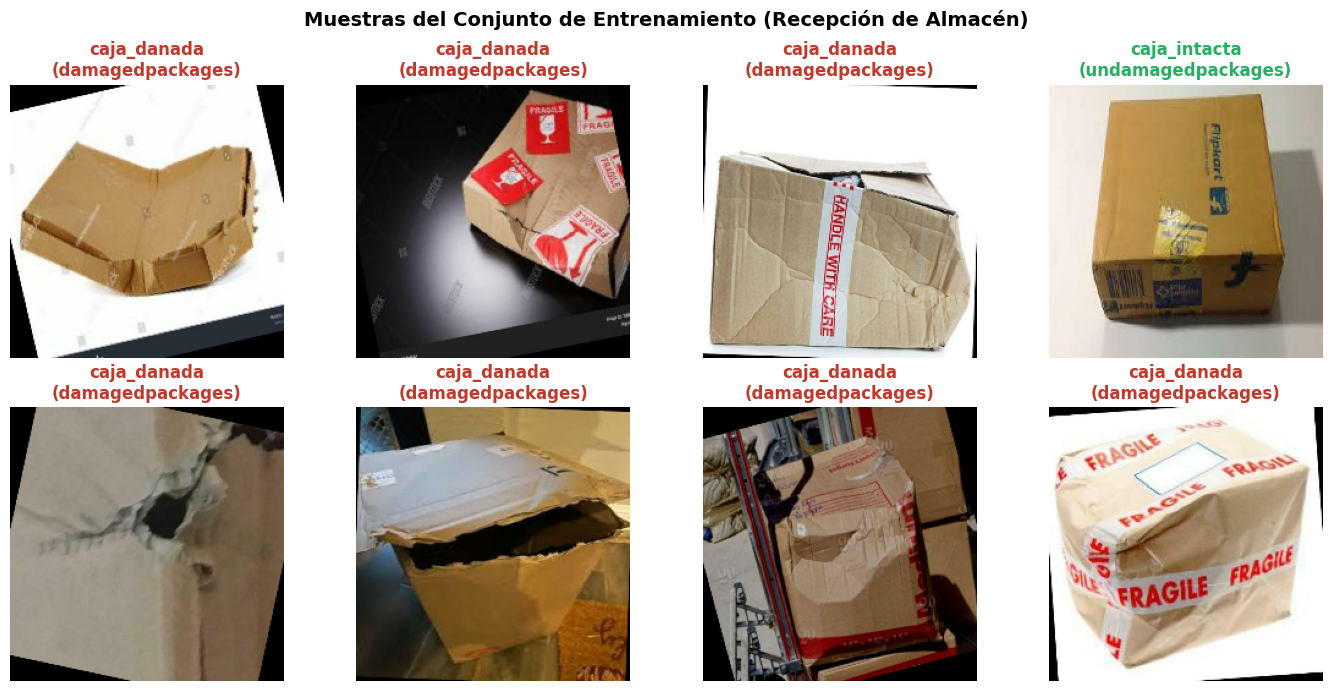

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))
for imagenes, etiquetas in train_ds_raw.take(1):
    for i in range(8):
        ax = plt.subplot(2, 4, i + 1)
        plt.imshow(imagenes[i].numpy().astype("uint8"))
        idx_clase = int(etiquetas[i].numpy())
        nombre_mostrar = etiquetas_espanol[idx_clase]
        color_titulo = "#c0392b" if nombre_mostrar == "caja_danada" else "#27ae60"
        plt.title(f"{nombre_mostrar}\n({clases_originales[idx_clase]})", color=color_titulo, fontweight="bold")
        plt.axis("off")

plt.suptitle("Muestras del Conjunto de Entrenamiento (Recepción de Almacén)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 4. Diseño de Arquitecturas CNN con Transferencia de Aprendizaje
Construimos ambos modelos siguiendo las mejores prácticas de ingeniería en Keras:

1. **Aumento de Datos (*Data Augmentation*) Integrado:**  
   Capas `RandomFlip`, `RandomRotation` y `RandomZoom` dentro del modelo (se activan automáticamente solo durante `fit()` y se desactivan en inferencia).
2. **Preprocesamiento Nativo sin Capas `Lambda`:**  
   - **EfficientNetB0** espera tensores RGB en el rango $[0, 255]$ y realiza el escalado internamente.
   - **ResNet50** requiere conversión $\text{RGB} \to \text{BGR}$ y centrado respecto a la media de ImageNet ($[-103.939, -116.779, -123.68]$). Lo implementamos mediante una capa fija `Conv2D(1x1, trainable=False)` con pesos exactos, lo cual evita usar funciones `Lambda` y garantiza que el archivo `.keras` exportado desde Colab pueda cargarse en cualquier computadora con `safe_mode=True`.
3. **Cabezal Clasificador (*Top Head*):**  
   `GlobalAveragePooling2D` $\to$ `BatchNormalization` $\to$ `Dense(128, ReLU)` $\to$ `Dropout(0.3)` $\to$ `Dense(1, Sigmoid)`.


In [18]:
%pip install keras

In [19]:
import numpy as np
import tensorflow as tf
import keras
from keras import layers, models
from keras.applications import EfficientNetB0, ResNet50

def crear_bloque_augmentacion() -> tf.keras.Sequential:
    """Capas de aumento de datos activas únicamente durante el entrenamiento."""
    return models.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.08),
    ], name="data_augmentation")


def construir_resnet50() -> tuple[keras.Model, keras.Model]:
    """Construye el modelo ResNet50 con Transfer Learning y preprocesamiento nativo."""
    inputs = layers.Input(shape=(224, 224, 3), name="imagen_rgb")
    x = crear_bloque_augmentacion()(inputs)

    # Preprocesamiento exacto de ResNet50 (RGB -> BGR y resta de media ImageNet) mediante Conv2D 1x1 fija
    prep_layer = layers.Conv2D(3, kernel_size=1, trainable=False, name="resnet50_preprocess")
    x = prep_layer(x)

    base_model = ResNet50(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False  # Congelado en Etapa 1

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.BatchNormalization(name="bn_head")(x)
    x = layers.Dense(128, activation="relu", name="dense_128")(x)
    x = layers.Dropout(0.3, name="dropout")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="salida_binaria")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="ResNet50_Transfer")

    # Fijar pesos exactos de caffe preprocess_input (RGB -> BGR y media ImageNet)
    w_bgr = np.array([[[[0.0, 0.0, 1.0], [0.0, 1.0, 0.0], [1.0, 0.0, 0.0]]]], dtype="float32")
    b_mean = np.array([-103.939, -116.779, -123.68], dtype="float32")
    model.get_layer("resnet50_preprocess").set_weights([w_bgr, b_mean])

    return model, base_model


def construir_efficientnetb0() -> tuple[keras.Model, keras.Model]:
    """Construye el modelo EfficientNetB0 con Transfer Learning."""
    inputs = layers.Input(shape=(224, 224, 3), name="imagen_rgb")
    x = crear_bloque_augmentacion()(inputs)

    # EfficientNetB0 incluye su propio escalado interno para entradas en [0, 255]
    base_model = EfficientNetB0(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False  # Congelado en Etapa 1

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.BatchNormalization(name="bn_head")(x)
    x = layers.Dense(128, activation="relu", name="dense_128")(x)
    x = layers.Dropout(0.3, name="dropout")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="salida_binaria")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="EfficientNetB0_Transfer")
    return model, base_model


modelo_resnet, base_resnet = construir_resnet50()
modelo_effnet, base_effnet = construir_efficientnetb0()

print(f"[OK] {modelo_resnet.name} construido | Total parámetros: {modelo_resnet.count_params():,}")
print(f"[OK] {modelo_effnet.name} construido | Total parámetros: {modelo_effnet.count_params():,}")

[OK] ResNet50_Transfer construido | Total parámetros: 23,858,317
[OK] EfficientNetB0_Transfer construido | Total parámetros: 4,218,788


## 5. Entrenamiento Comparativo en 2 Etapas (Feature Extraction + Fine-Tuning)
Para maximizar la precisión en la GPU de Google Colab, aplicamos el protocolo estándar de Transfer Learning en dos fases para cada arquitectura:

1. **Fase 1 — Extracción de Características (`EPOCHS_FASE1 = 8`, `lr = 1e-3`):**  
   Se mantiene congelada toda la base preentrenada en ImageNet y se entrenan únicamente las capas densas superiores.
2. **Fase 2 — Ajuste Fino / *Fine-Tuning* (`EPOCHS_FASE2 = 7`, `lr = 1e-5`):**  
   Se descongelan las últimas **20 capas** del backbone (manteniendo congeladas las capas `BatchNormalization` para preservar las estadísticas de ImageNet) y se entrena con una tasa de aprendizaje 100 veces menor.


In [20]:
EPOCHS_FASE1 = 8
EPOCHS_FASE2 = 7


def entrenar_en_dos_fases(
    model: tf.keras.Model,
    base_model: tf.keras.Model,
    nombre: str
) -> dict[str, list[float]]:
    """Ejecuta Fase 1 (Feature Extraction) y Fase 2 (Fine-Tuning) concatenando el historial."""
    print("\n" + "=" * 75)
    print(f" 🚀 ENTRENANDO MODELO: {nombre}")
    print("=" * 75)

    # --- FASE 1: Cabezal Clasificador (Backbone congelado) ---
    print(f"\n[Fase 1/2] Extracción de características ({EPOCHS_FASE1} épocas, lr=1e-3)...")
    base_model.trainable = False
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    cb_fase1 = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ]

    hist1 = model.fit(
        train_ds,
        validation_data=valid_ds,
        epochs=EPOCHS_FASE1,
        class_weight=class_weights,
        callbacks=cb_fase1
    )

    # --- FASE 2: Fine-Tuning de las últimas 20 capas ---
    print(f"\n[Fase 2/2] Fine-Tuning de las últimas 20 capas ({EPOCHS_FASE2} épocas, lr=1e-5)...")
    base_model.trainable = True
    for layer in base_model.layers[:-20]:
        layer.trainable = False
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    cb_fase2 = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ]

    hist2 = model.fit(
        train_ds,
        validation_data=valid_ds,
        epochs=EPOCHS_FASE2,
        class_weight=class_weights,
        callbacks=cb_fase2
    )

    # Combinar historiales de ambas fases para graficar
    historial_completo = {}
    for k in hist1.history:
        historial_completo[k] = hist1.history[k] + hist2.history[k]

    return historial_completo


hist_resnet = entrenar_en_dos_fases(modelo_resnet, base_resnet, "ResNet50")
hist_effnet = entrenar_en_dos_fases(modelo_effnet, base_effnet, "EfficientNetB0")



 🚀 ENTRENANDO MODELO: ResNet50

[Fase 1/2] Extracción de características (8 épocas, lr=1e-3)...
Epoch 1/8
117/117 ━━━━━━━━━━━━━━━━━━━━ 39s 183ms/step - accuracy: 0.9121 - loss: 0.2603 - val_accuracy: 0.9570 - val_loss: 0.1787 - learning_rate: 0.0010
Epoch 2/8
117/117 ━━━━━━━━━━━━━━━━━━━━ 18s 155ms/step - accuracy: 0.9615 - loss: 0.1056 - val_accuracy: 0.9404 - val_loss: 0.2032 - learning_rate: 0.0010
Epoch 3/8
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.9707 - loss: 0.0811
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
117/117 ━━━━━━━━━━━━━━━━━━━━ 18s 153ms/step - accuracy: 0.9730 - loss: 0.0766 - val_accuracy: 0.9437 - val_loss: 0.2282 - learning_rate: 0.0010
Epoch 4/8
117/117 ━━━━━━━━━━━━━━━━━━━━ 17s 148ms/step - accuracy: 0.9765 - loss: 0.0619 - val_accuracy: 0.9536 - val_loss: 0.2299 - learning_rate: 5.0000e-04
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.

[Fase 2/2] Fine-Tuning de las últimas 20 capas

## 6. Curvas de Aprendizaje Comparativas (Entrenamiento vs. Validación)
Inspeccionamos la evolución de la función de pérdida (*Binary Crossentropy Loss*) y la exactitud (*Accuracy*) a través de las épocas para diagnosticar la convergencia y descartar sobreajuste (*overfitting*).


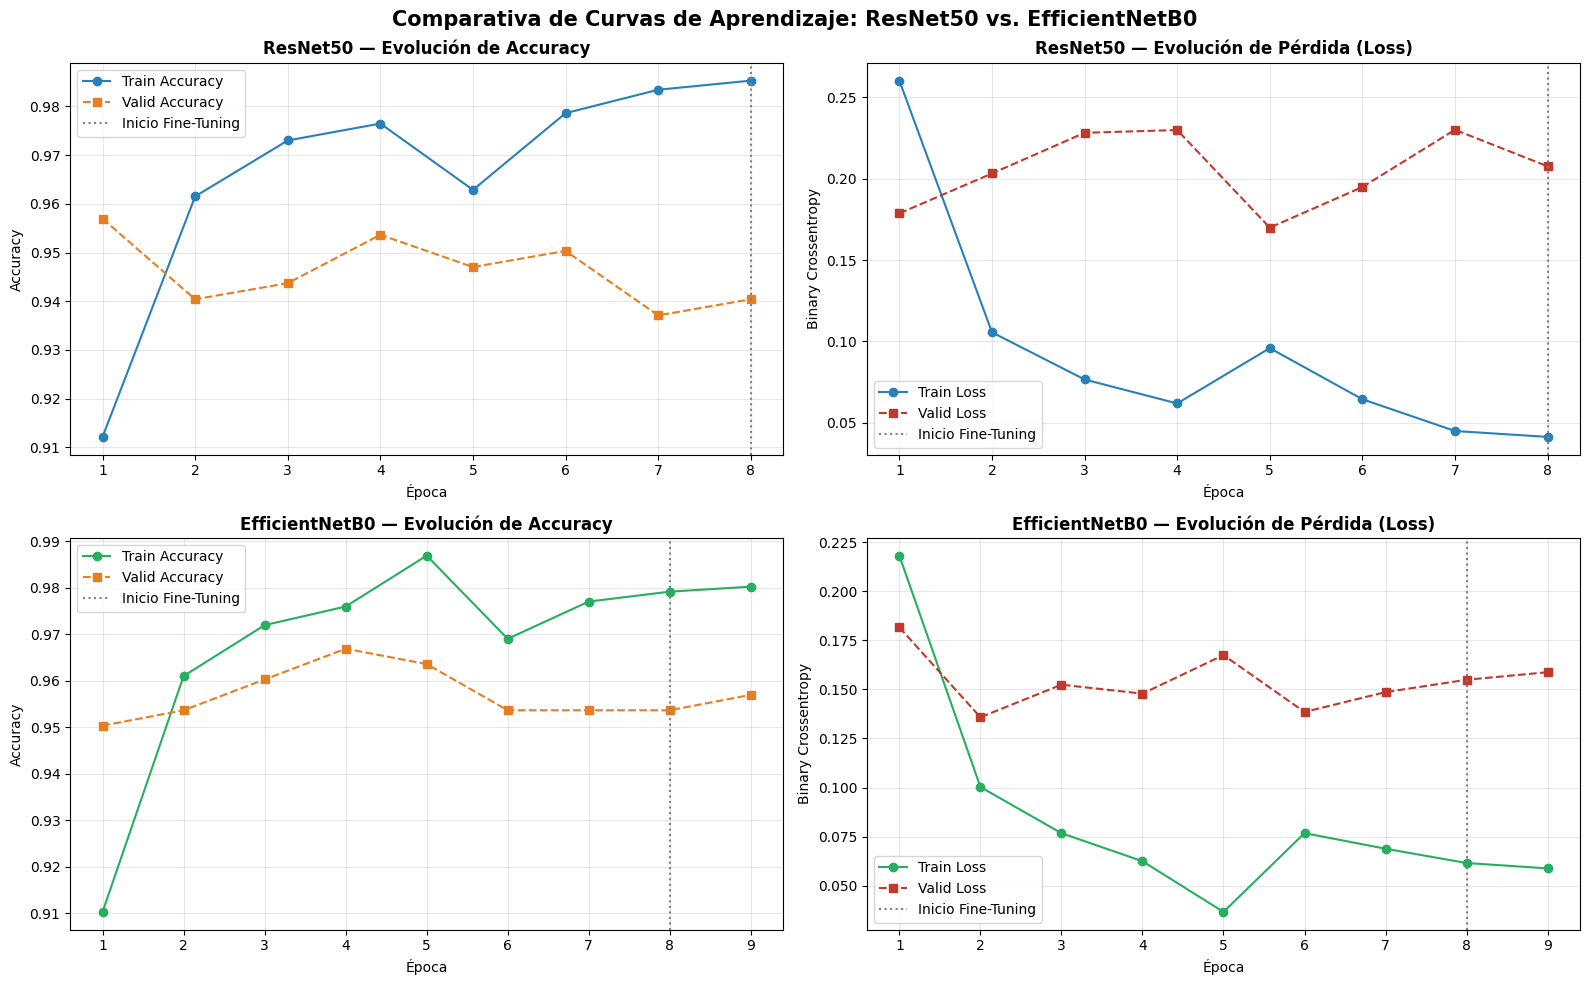

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

historiales = [
    ("ResNet50", hist_resnet, "#2980b9"),
    ("EfficientNetB0", hist_effnet, "#27ae60")
]

for fila, (nombre, hist, color) in enumerate(historiales):
    epocas = range(1, len(hist["accuracy"]) + 1)

    # Gráfica de Accuracy
    axes[fila, 0].plot(epocas, hist["accuracy"], "o-", color=color, label="Train Accuracy")
    axes[fila, 0].plot(epocas, hist["val_accuracy"], "s--", color="#e67e22", label="Valid Accuracy")
    axes[fila, 0].axvline(x=EPOCHS_FASE1, color="gray", linestyle=":", label="Inicio Fine-Tuning")
    axes[fila, 0].set_title(f"{nombre} — Evolución de Accuracy", fontweight="bold")
    axes[fila, 0].set_xlabel("Época")
    axes[fila, 0].set_ylabel("Accuracy")
    axes[fila, 0].legend()
    axes[fila, 0].grid(True, alpha=0.3)

    # Gráfica de Loss
    axes[fila, 1].plot(epocas, hist["loss"], "o-", color=color, label="Train Loss")
    axes[fila, 1].plot(epocas, hist["val_loss"], "s--", color="#c0392b", label="Valid Loss")
    axes[fila, 1].axvline(x=EPOCHS_FASE1, color="gray", linestyle=":", label="Inicio Fine-Tuning")
    axes[fila, 1].set_title(f"{nombre} — Evolución de Pérdida (Loss)", fontweight="bold")
    axes[fila, 1].set_xlabel("Época")
    axes[fila, 1].set_ylabel("Binary Crossentropy")
    axes[fila, 1].legend()
    axes[fila, 1].grid(True, alpha=0.3)

plt.suptitle("Comparativa de Curvas de Aprendizaje: ResNet50 vs. EfficientNetB0", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


## 7. Evaluación en el Conjunto de Prueba (`test`) — Las 5 Evidencias de la Rúbrica
Evaluamos ambos modelos sobre el conjunto independiente de prueba (`test`: 102 imágenes balanceadas 50/50 que no participaron ni en el entrenamiento ni en la validación) y calculamos las **5 evidencias obligatorias**:
1. **Accuracy**
2. **Precision**
3. **Recall**
4. **F1-Score**
5. **Matriz de Confusión**


=== TABLA COMPARATIVA DE LAS 4 MÉTRICAS CUANTITATIVAS EN TEST ===


,Modelo CNN,1. Accuracy,2. Precision (Pond.),3. Recall (Pond.),4. F1-Score (Pond.)
0,EfficientNetB0 (Transfer Learning),95.1%,95.1%,95.1%,95.1%
1,ResNet50 (Transfer Learning),92.2%,92.2%,92.2%,92.2%



🏆 Modelo Visual Ganador: EfficientNetB0 (Transfer Learning)

REPORTE DE CLASIFICACIÓN DETALLADO — ResNet50 (Transfer Learning)
              precision    recall  f1-score   support

 caja_danada       0.94      0.90      0.92        51
caja_intacta       0.91      0.94      0.92        51

    accuracy                           0.92       102
   macro avg       0.92      0.92      0.92       102
weighted avg       0.92      0.92      0.92       102


REPORTE DE CLASIFICACIÓN DETALLADO — EfficientNetB0 (Transfer Learning)
              precision    recall  f1-score   support

 caja_danada       0.94      0.96      0.95        51
caja_intacta       0.96      0.94      0.95        51

    accuracy                           0.95       102
   macro avg       0.95      0.95      0.95       102
weighted avg       0.95      0.95      0.95       102



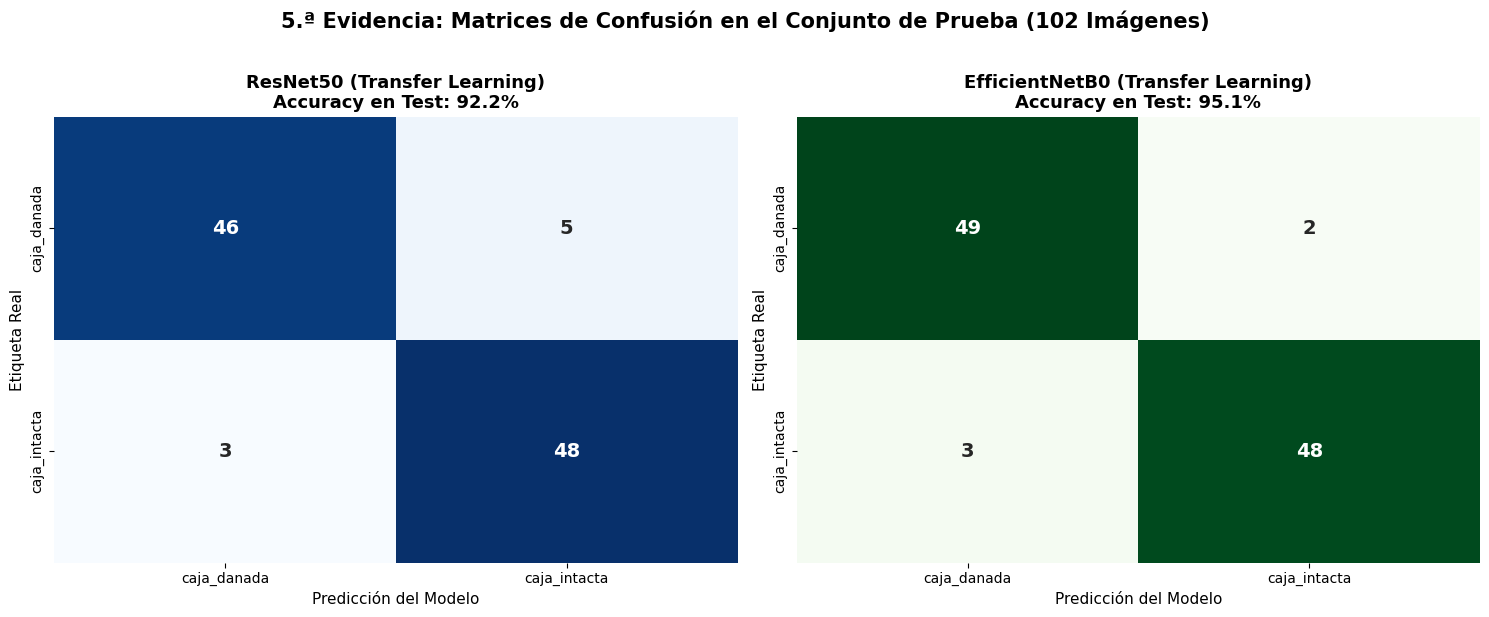

In [27]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Evaluar el modelo en el conjunto de prueba
# Extraer etiquetas reales del conjunto de prueba
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)

modelos_evaluar = {
    "ResNet50 (Transfer Learning)": modelo_resnet,
    "EfficientNetB0 (Transfer Learning)": modelo_effnet,
}

resultados_test = []
predicciones_test = {}
probabilidades_test = {}

for nombre, mod in modelos_evaluar.items():
    probs = mod.predict(test_ds, verbose=0).flatten()
    preds = (probs >= 0.5).astype(int)

    probabilidades_test[nombre] = probs
    predicciones_test[nombre] = preds

    acc = accuracy_score(y_true, preds)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, preds, average="weighted", zero_division=0)

    resultados_test.append({
        "Modelo CNN": nombre,
        "1. Accuracy": f"{acc:.1%}",
        "2. Precision (Pond.)": f"{prec:.1%}",
        "3. Recall (Pond.)": f"{rec:.1%}",
        "4. F1-Score (Pond.)": f"{f1:.1%}",
        "_f1_raw": f1,
        "_acc_raw": acc,
    })

# Ordenar por F1-Score y Accuracy descendente para elegir al ganador
df_comparativa_vision = (
    pd.DataFrame(resultados_test)
    .sort_values(by=["_f1_raw", "_acc_raw"], ascending=[False, False])
    .drop(columns=["_f1_raw", "_acc_raw"])
    .reset_index(drop=True)
)

print("=== TABLA COMPARATIVA DE LAS 4 MÉTRICAS CUANTITATIVAS EN TEST ===")
display(df_comparativa_vision)

nombre_ganador = df_comparativa_vision.iloc[0]["Modelo CNN"]
modelo_ganador = modelos_evaluar[nombre_ganador]
print(f"\n🏆 Modelo Visual Ganador: {nombre_ganador}")

# Reportes detallados por clase para ambos modelos
for nombre, preds in predicciones_test.items():
    print("\n" + "=" * 75)
    print(f"REPORTE DE CLASIFICACIÓN DETALLADO — {nombre}")
    print("=" * 75)
    print(classification_report(y_true, preds, target_names=etiquetas_espanol, zero_division=0))

# Evidencia 5: Matrices de Confusión lado a lado
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
paletas = ["Blues", "Greens"]

for idx, (nombre, preds) in enumerate(predicciones_test.items()):
    cm = confusion_matrix(y_true, preds)
    acc = accuracy_score(y_true, preds)

    sns.heatmap(
        cm, annot=True, fmt="d", cmap=paletas[idx],
        xticklabels=etiquetas_espanol, yticklabels=etiquetas_espanol,
        ax=axes[idx], cbar=False, annot_kws={"size": 14, "weight": "bold"}
    )
    axes[idx].set_title(f"{nombre}\nAccuracy en Test: {acc:.1%}", fontsize=13, fontweight="bold")
    axes[idx].set_xlabel("Predicción del Modelo", fontsize=11)
    axes[idx].set_ylabel("Etiqueta Real", fontsize=11)

plt.suptitle("5.ª Evidencia: Matrices de Confusión en el Conjunto de Prueba (102 Imágenes)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


## 8. Galería de Inspección Visual con el Modelo Ganador
Mostramos predicciones reales del modelo ganador sobre imágenes del conjunto `test` junto con el nivel de confianza asignado por la red.


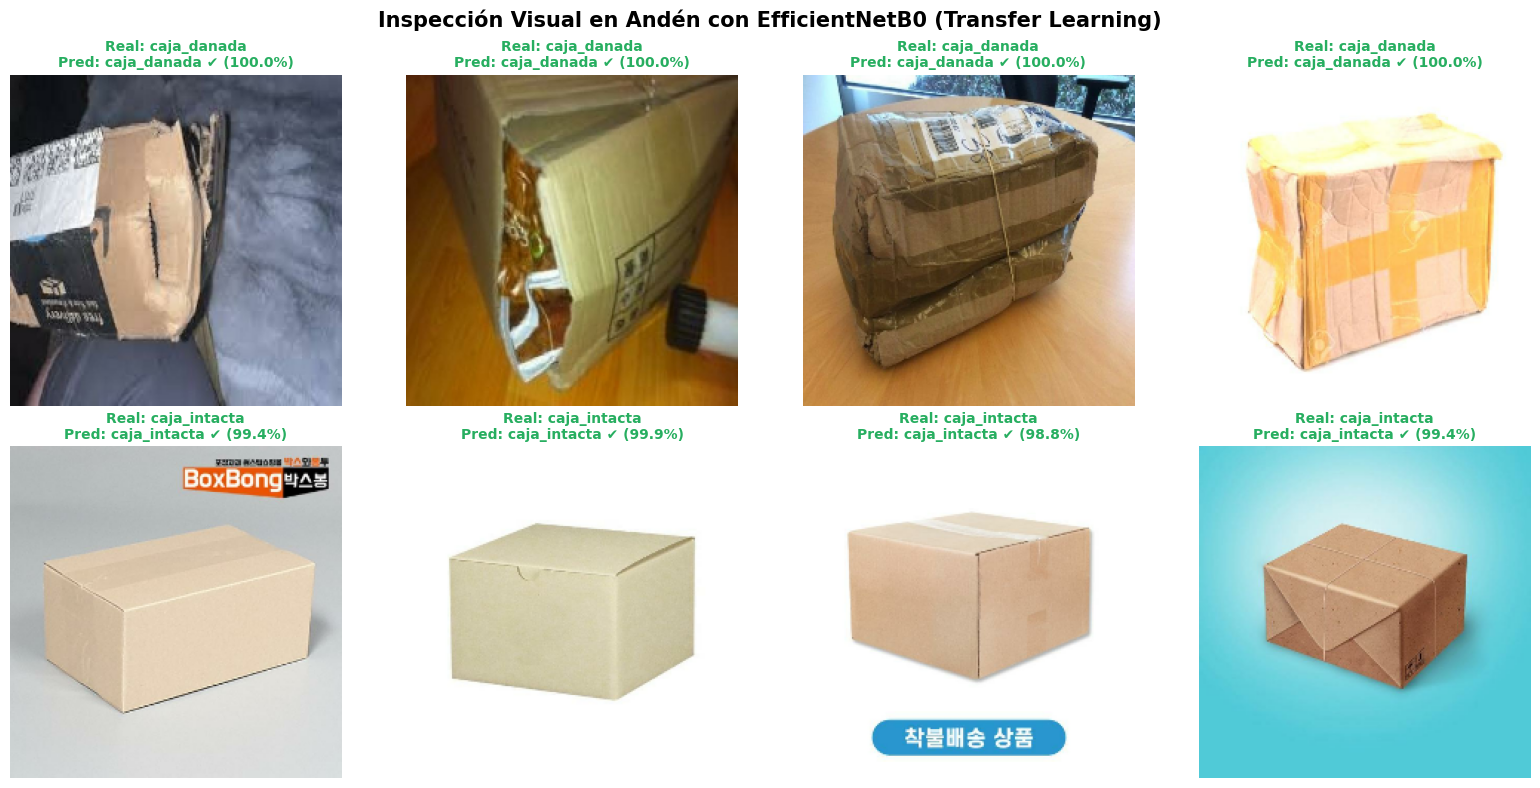

In [28]:
# Reunir todas las imágenes de test para muestrear de ambas clases
imagenes_test_lista = []
etiquetas_test_lista = []
for imgs, lbls in test_ds_raw:
    imagenes_test_lista.append(imgs.numpy())
    etiquetas_test_lista.append(lbls.numpy())

X_test_imgs = np.concatenate(imagenes_test_lista, axis=0)
y_test_lbls = np.concatenate(etiquetas_test_lista, axis=0)

probs_ganador = probabilidades_test[nombre_ganador]
preds_ganador = predicciones_test[nombre_ganador]

# Seleccionar 4 muestras de la clase 0 (dañada) y 4 de la clase 1 (intacta)
idx_c0 = np.where(y_test_lbls == 0)[0][:4]
idx_c1 = np.where(y_test_lbls == 1)[0][:4]
indices_muestra = np.concatenate([idx_c0, idx_c1])

plt.figure(figsize=(16, 8))
for i, idx_img in enumerate(indices_muestra):
    ax = plt.subplot(2, 4, i + 1)
    plt.imshow(X_test_imgs[idx_img].astype("uint8"))

    real_idx = int(y_test_lbls[idx_img])
    pred_idx = int(preds_ganador[idx_img])
    prob_c1 = float(probs_ganador[idx_img])
    confianza = prob_c1 if pred_idx == 1 else (1.0 - prob_c1)

    real_txt = etiquetas_espanol[real_idx]
    pred_txt = etiquetas_espanol[pred_idx]
    acierto = (real_idx == pred_idx)

    color = "#27ae60" if acierto else "#c0392b"
    simbolo = "✔" if acierto else "✘"
    plt.title(
        f"Real: {real_txt}\nPred: {pred_txt} {simbolo} ({confianza:.1%})",
        color=color, fontweight="bold", fontsize=10
    )
    plt.axis("off")

plt.suptitle(f"Inspección Visual en Andén con {nombre_ganador}", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


## 9. Persistencia del Modelo Ganador y Descarga para el Asistente
Guardamos el modelo ganador en formato nativo de Keras (`models/clasificador_cajas.keras`) junto con su archivo de configuración (`models/metadata_vision.json`).

> 📥 **Si estás ejecutando en Google Colab:**  
> Al finalizar esta celda, se descargarán automáticamente a tu computadora los archivos `clasificador_cajas.keras` y `metadata_vision.json`. Solo colócalos dentro de la carpeta `models/` de tu proyecto local.


In [35]:
import json
from pathlib import Path

dir_modelos = Path("models")
dir_modelos.mkdir(parents=True, exist_ok=True)

ruta_modelo_vision = dir_modelos / "clasificador_cajas.keras"
ruta_metadata_vision = dir_modelos / "metadata_vision.json"

# 1. Guardar modelo ganador
modelo_ganador.save(ruta_modelo_vision)
print(f"[OK] Modelo ganador '{nombre_ganador}' guardado en: {ruta_modelo_vision}")

# 2. Guardar metadatos de clases y configuración
metadata = {
    "modelo_ganador": nombre_ganador,
    "img_size": list(IMG_SIZE),
    "clases_originales": clases_originales,
    "etiquetas_espanol": etiquetas_espanol,
    "mapa_indices": {str(i): etiquetas_espanol[i] for i in range(len(etiquetas_espanol))},
    "umbral_binario": 0.5
}
with open(ruta_metadata_vision, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)
print(f"[OK] Metadatos exportados en: {ruta_metadata_vision}")

# 3. Verificación de recarga e inferencia individual
modelo_recargado = tf.keras.models.load_model(ruta_modelo_vision)
muestra_prueba = X_test_imgs[0:1]
prob_prueba = float(modelo_recargado.predict(muestra_prueba, verbose=0)[0][0])
clase_pred_idx = 1 if prob_prueba >= 0.5 else 0
confianza_prueba = prob_prueba if clase_pred_idx == 1 else (1.0 - prob_prueba)

print("\nPrueba de recarga exitosa:")
print(f"  Clase predicha : {etiquetas_espanol[clase_pred_idx]} (confianza: {confianza_prueba:.1%})")

# 4. Descarga automática al navegador si se ejecuta en Google Colab
if EN_COLAB:
    from google.colab import files
    print("\n[INFO] Iniciando descarga de los artefactos a tu equipo local...")
    files.download(str(ruta_modelo_vision))
    files.download(str(ruta_metadata_vision))


[OK] Modelo ganador 'EfficientNetB0 (Transfer Learning)' guardado en: models/clasificador_cajas.keras
[OK] Metadatos exportados en: models/metadata_vision.json



Prueba de recarga exitosa:
  Clase predicha : caja_danada (confianza: 100.0%)

[INFO] Iniciando descarga de los artefactos a tu equipo local...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>